In [1]:
import sys,os
ROOT = r"\\172.22.48.112\Sumner_HHEAR_Lichtveld\4a. Data_LC-MS_OrbiTrap\5-Statistical Analyses\Julian Analysis\July-2026\Analysis"
sys.path.append(os.path.abspath(ROOT))
from functions.ST002118 import *

In [11]:
untargeted_data = pd.read_csv(r"\\172.22.48.112\Sumner_HHEAR_Lichtveld\4a. Data_LC-MS_OrbiTrap\5-Statistical Analyses\Julian Analysis\July-2026\Data\Untargeted\ST002118_Untargeted_Reference_Copy.csv").set_index("SID_MW")
targeted_data = pd.read_excel(r"\\172.22.48.112\Sumner_HHEAR_Lichtveld\4a. Data_LC-MS_OrbiTrap\5-Statistical Analyses\Julian Analysis\July-2026\Data\Targeted\TARGETED_DATA_WIDE_07132026.xlsx")
targeted_data = targeted_data.set_index("SID_MW")
annotations = pd.read_excel(r"\\172.22.48.112\Sumner_HHEAR_Lichtveld\4a. Data_LC-MS_OrbiTrap\5-Statistical Analyses\Julian Analysis\July-2026\Data\Annotations\All ADAP IDs and Annotations Lichtveld 09JUL26.xlsx")
annotations = annotations.set_index("query_signal_name")
epi_data = pd.read_csv(r"\\172.22.48.112\Sumner_HHEAR_Lichtveld\4a. Data_LC-MS_OrbiTrap\5-Statistical Analyses\Julian Analysis\July-2026\Data\EPI_DATA\2254_EPI_DATA.csv")

In [12]:
targeted_data_t1 = targeted_data[targeted_data['Trimester_r'] == "1st/2nd"].drop(columns=['Trimester_r','CompositeKey'])
untargeted_data_t1 = untargeted_data[untargeted_data['Trimester'] == "1st/2nd"].drop(columns=['PID','Trimester'])
untargeted_data_t1 = untargeted_data_t1.loc[targeted_data_t1.index,:]

# Spearman Correlation All Peaks x Metals

In [43]:
from scipy.stats import spearmanr
import pandas as pd

X = untargeted_data_t1

results = {}

for metal in targeted_data_t1.columns:
    rho = []
    pval = []

    for feature in X.columns:
        r, p = spearmanr(targeted_data_t1[metal], X[feature], nan_policy="omit")
        rho.append(r)
        pval.append(p)

    results[metal] = pd.DataFrame({
        "feature": X.columns,
        "rho": rho,
        "p_value": pval
    }).set_index("feature")

In [ ]:
# with pd.ExcelWriter("metal_spearman_results.xlsx", engine="openpyxl") as writer:
#     for id,df in results.items():
#         df = pd.merge(df,annotations,right_index=True,left_index=True)
#         df = df.sort_values(by=['p_value'],ascending=True)
#         df.to_excel(writer,sheet_name=id[:-8])

# Mercury

In [27]:
# Mercury Differential Abundance
# EPA Cutoff (5.8 ng/mL)
Hg = targeted_data[['Hg (ng/mL)','Trimester_r']].copy()
Hg['EPA Cutoff'] = np.where(targeted_data['Hg (ng/mL)'] <= 5.8,"normal",'high')

hg_untargeted = untargeted_data.loc[untargeted_data.index.intersection(Hg.index),:]
hg_untargeted_t1 = hg_untargeted[hg_untargeted['Trimester'] == "1st/2nd"]
hg_untargeted_t1 = hg_untargeted_t1.drop(columns=['Trimester',"PID"])

hg_untargeted_t2 = hg_untargeted[hg_untargeted['Trimester'] == "3rd"]
hg_untargeted_t2 = hg_untargeted_t2.drop(columns=['Trimester',"PID"])

## Figures

EPA Cutoff
normal    253
high       57
Name: count, dtype: int64


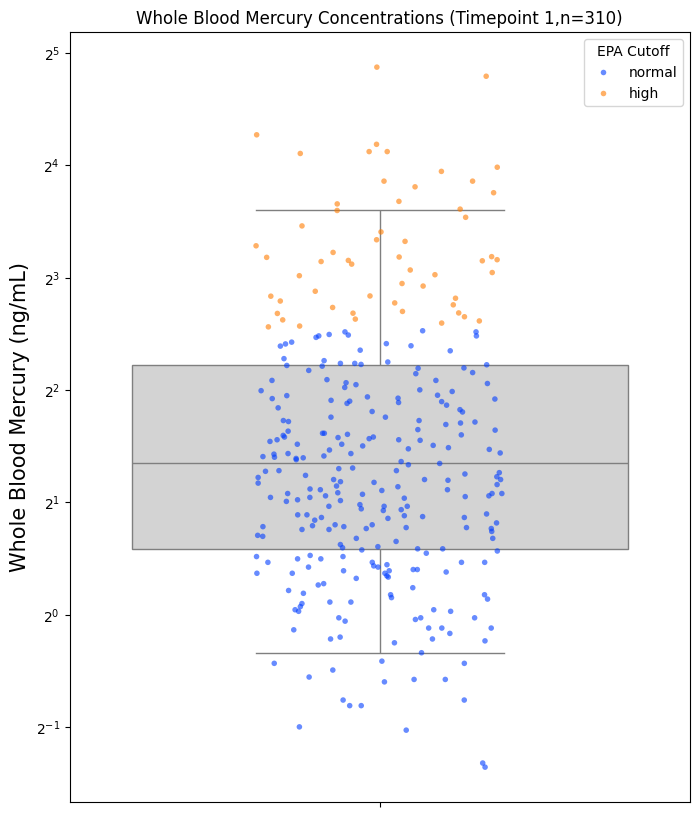

In [10]:
hg_t1 = Hg[Hg['Trimester_r'] == "1st/2nd"].copy()
samples = hg_t1.shape[0]
print(hg_t1['EPA Cutoff'].value_counts())
fig, ax = plt.subplots(figsize=(8, 10))
sns.boxplot(
    data=hg_t1,
    y="Hg (ng/mL)",
    whis=[5, 95],
    fliersize=0,
    color="lightgray",
    ax=ax
)

sns.stripplot(
    data=hg_t1,
    y="Hg (ng/mL)",
    hue="EPA Cutoff",
    jitter=0.2,
    alpha=0.6,
    size=4,
    palette="bright",
    ax=ax
)

ax.set_yscale("log", base=2)
ax.set_ylabel("Whole Blood Mercury (ng/mL)", fontsize=15)
ax.set_xlabel("")
ax.set_title(f"Whole Blood Mercury Concentrations (Timepoint 1,n={samples})")

plt.show()

EPA Cutoff
normal    204
high       42
Name: count, dtype: int64


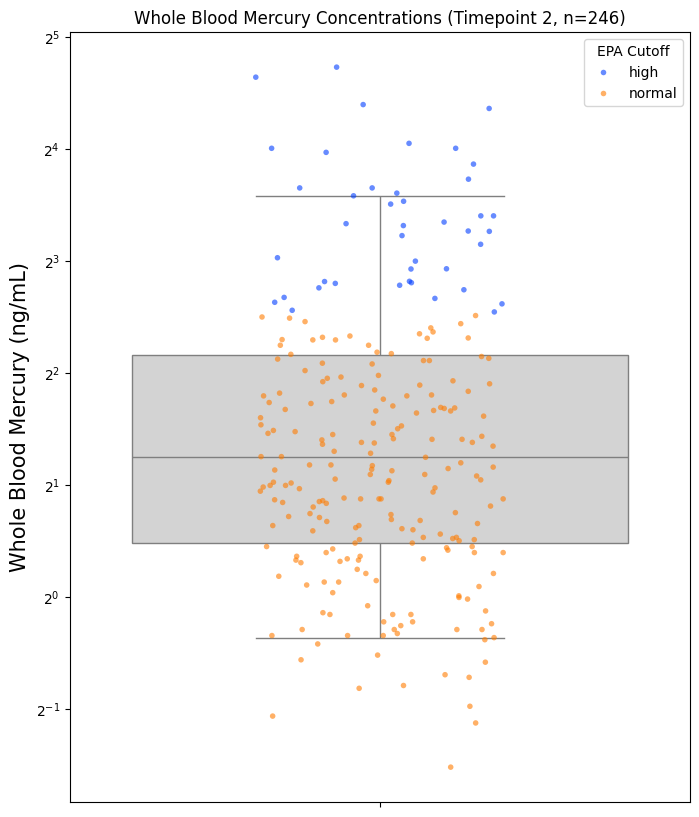

In [26]:
hg_t2 = Hg[Hg['Trimester_r'] == "3rd"]
samples = hg_t2.shape[0]
print(hg_t2['EPA Cutoff'].value_counts())
fig, ax = plt.subplots(figsize=(8, 10))
sns.boxplot(
    data=hg_t2,
    y="Hg (ng/mL)",
    whis=[5, 95],
    fliersize=0,
    color="lightgray",
    ax=ax
)

sns.stripplot(
    data=hg_t2,
    y="Hg (ng/mL)",
    hue="EPA Cutoff",
    jitter=0.2,
    alpha=0.6,
    size=4,
    palette="bright",
    ax=ax
)

ax.set_yscale("log", base=2)
ax.set_ylabel("Whole Blood Mercury (ng/mL)", fontsize=15)
ax.set_xlabel("")
ax.set_title(f"Whole Blood Mercury Concentrations (Timepoint 2, n={samples})")

plt.show()

## Differential Abundance

In [ ]:
BIOMARKERS = {"EPA[OL-1]":["15.53_285.2210m/z","15.91_302.2244n"],
              "ArachidonicAcid[OL-1]":["16.07_269.2260m/z","16.23_304.2395n"],
              "DHA[OL-1]":["16.21_328.2395n"],
              "DPA[OL-1]": ["16.39_330.2554n"],
              "AdrenicAcid[OL-1]":["16.64_332.2711n"],
              "LinoleicAcid[OL-1]":["16.24_280.2401n","16.43_263.2366m/z"],
              "Linolenic[OL-1]":["15.91_278.2243n","16.45_306.2554n"],
              "TMAO[OL-1]":["0.64_75.0684n"],
              "1-MethylHistidine[OL-2b]": ["1.67_169.0851n"]
              }
signal_to_name = {
    signal: name
    for name, signals in BIOMARKERS.items()
    for signal in signals
}

{'15.53_285.2210m/z': 'EPA[OL-1]',
 '15.91_302.2244n': 'EPA[OL-1]',
 '16.07_269.2260m/z': 'ArachidonicAcid[OL-1]',
 '16.23_304.2395n': 'ArachidonicAcid[OL-1]',
 '16.21_328.2395n': 'DHA[OL-1]',
 '16.39_330.2554n': 'DPA[OL-1]',
 '16.64_332.2711n': 'AdrenicAcid[OL-1]',
 '16.24_280.2401n': 'LinoleicAcid[OL-1]',
 '16.43_263.2366m/z': 'LinoleicAcid[OL-1]',
 '15.91_278.2243n': 'Linolenic[OL-1]',
 '16.45_306.2554n': 'Linolenic[OL-1]',
 '0.64_75.0684n': 'TMAO[OL-1]',
 '1.67_169.0851n': '1-MethylHistidine[OL-2b]'}

In [28]:
obj = DifferentialAbundance(data=hg_untargeted_t1,metadata=hg_t1)
welch_Hg = obj.fit(contrast=("EPA Cutoff","high","normal"),applylog=True,equal_var=False)
welch_Hg = DifferentialAbundance.volcano_plot(welch_Hg,fc_thresh=0,use_adjusted=False,backend='plotly',title='Mercury Exposure (EPA Cutoff)')
welch_Hg_t1 = welch_Hg[(welch_Hg['high_mean'] != 0) & (welch_Hg['normal_mean'] != 0)]


obj = DifferentialAbundance(data=hg_untargeted_t2,metadata=hg_t2)
welch_Hg = obj.fit(contrast=("EPA Cutoff","high","normal"),applylog=True,equal_var=False)
welch_Hg = DifferentialAbundance.volcano_plot(welch_Hg,fc_thresh=0,use_adjusted=False,backend='plotly',title='Mercury Exposure (EPA Cutoff)')
welch_Hg_t2 = welch_Hg[(welch_Hg['high_mean'] != 0) & (welch_Hg['normal_mean'] != 0)]

Contrast: EPA Cutoff[high vs normal]  (high: n=57, normal: n=253)  test=ttest  equal_var=False (Welch)  dof=per-feature


Contrast: EPA Cutoff[high vs normal]  (high: n=42, normal: n=204)  test=ttest  equal_var=False (Welch)  dof=per-feature


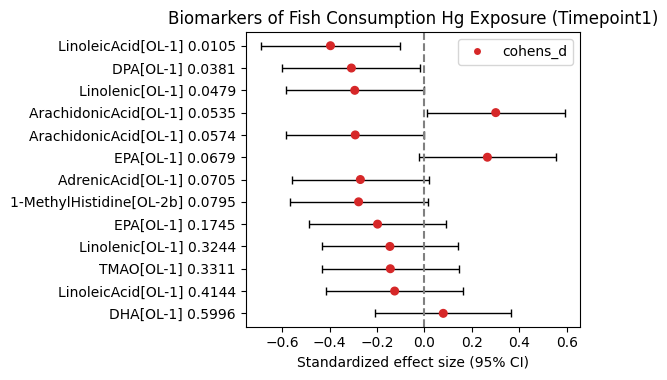

In [59]:
from itertools import chain
bm = welch_Hg_t1.loc[list(chain.from_iterable(BIOMARKERS.values())),:]
bm.index = bm.index.map(signal_to_name)
bm.index = bm.index + " " + np.round(bm['p_value'],4).astype(str)
forest_plot = DifferentialAbundance.forest_plot(bm,effect_measure='cohens_d',backend='seaborn',title='Biomarkers of Fish Consumption Hg Exposure (Timepoint1)',equal_var=False)

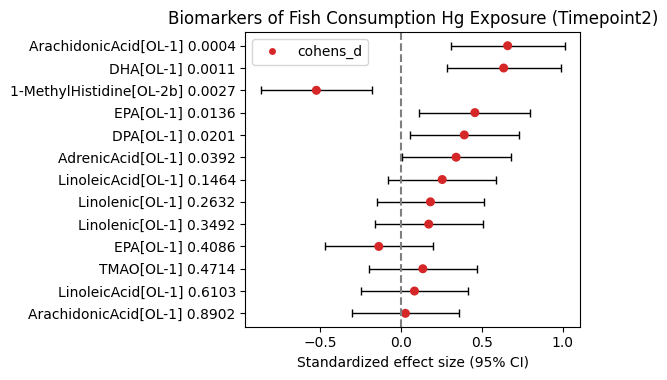

In [58]:
bm = welch_Hg_t2.loc[list(chain.from_iterable(BIOMARKERS.values())),:]
bm.index = bm.index.map(signal_to_name)
bm.index = bm.index + " " + np.round(bm['p_value'],4).astype(str)
forest_plot = DifferentialAbundance.forest_plot(bm,effect_measure='cohens_d',backend='seaborn',title='Biomarkers of Fish Consumption Hg Exposure (Timepoint2)',equal_var=False)

In [88]:
forest_plot = DifferentialAbundance.forest_plot(welch_Hg[welch_Hg['highest_OL'] == "OL_1"],top_n=20,effect_measure='cohens_d',backend='plotly')
forest_plot = pd.merge(forest_plot,annotations,right_index=True,left_index=True,how='inner')

In [89]:
import plotly.express as px
forest_plot['feature'] = forest_plot.index
forest_plot = forest_plot.iloc[:30,:]
forest_plot['top_id'] = forest_plot['list_all_ids'].str.split("|").str[0]
fig = px.scatter(
    forest_plot,
    x="effect_size",
    y="top_id",
    error_x=forest_plot["ci_upper"] - forest_plot["effect_size"],
    error_x_minus=forest_plot["effect_size"] - forest_plot["ci_lower"],
)

fig.add_vline(
    x=0,
    line_dash="dash",
    line_color="black"
)

fig.update_layout(
    title="Forest Plot",
    xaxis_title="Effect Size (Cohen's d)",
    yaxis_title="",
    template="simple_white",
    height=800
)
fig.add_shape(
    type="line",
    x0=0,
    x1=0,
    y0=0,
    y1=1,
    xref="x",
    yref="paper",
    line=dict(
        color="black",
        width=1,
        dash="dot"
    )
)
fig.show()

In [86]:
print(forest_plot["effect_size"].min(), forest_plot["effect_size"].max())

-0.5854302833560432 0.68396293117109


In [77]:
forest_plot.index

Index(['123979 (3-Carboxy-4-methyl-5-propyl-2-furanpropionic acid) [OL_1] ',
       '439939 (2-Hydroxyglutaric acid) [OL_1] ',
       '92832 (N6-Acetyl-L-lysine) [OL_1] ', '6613 (PANTOTHENATE) [OL_1] ',
       '93072 (Ureidosuccinic acid) [OL_1] ',
       '152204 (N-Acetylthreonine) [OL_1] ', '33032 (Glutamic acid) [OL_1] ',
       '638024 (Piperine) [OL_1] ', '811 (ITACONATE) [OL_1] ',
       '98681 (Propionyl Glycine) [OL_1] ', '71082 (ORNITHINE) [OL_1] ',
       '91745 (Cinmethylin) [OL_1] ', '6029 (Uridine) [OL_1] ',
       '11163 (Glycyl-Glycine) [OL_1] ', '2266 (Nonanedioic acid) [OL_1] ',
       '11500 (N-Benzylacetamide) [OL_1] ',
       '150964 (Arginyl-Phenylalanine) [OL_1] ', '145742 (Proline) [OL_1] ',
       '80777 (N-(2,5-Dimethoxyphenyl)-3-oxobutanamide) [OL_1] ',
       '99288 (L-Alloisoleucine) [OL_1] '],
      dtype='object')

# Lead

In [16]:
# Lead Differential Abundance 
# EPA Cutoff (3.5 ug/dL)
Pb = targeted_data[['Pb (ug/dL)','Trimester_r']]
Pb['EPA Cutoff'] = np.where(targeted_data['Pb (ug/dL)'] <= 3.5,"normal",'high')
Pb['EPA Cutoff'].value_counts()

pb_untargeted = untargeted_data.loc[untargeted_data.index.intersection(Pb.index),:]
pb_untargeted_t1 = pb_untargeted[pb_untargeted['Trimester'] == "1st/2nd"]
pb_untargeted_t1 = pb_untargeted_t1.drop(columns=['Trimester',"PID"])

EPA Cutoff
normal    261
high       49
Name: count, dtype: int64


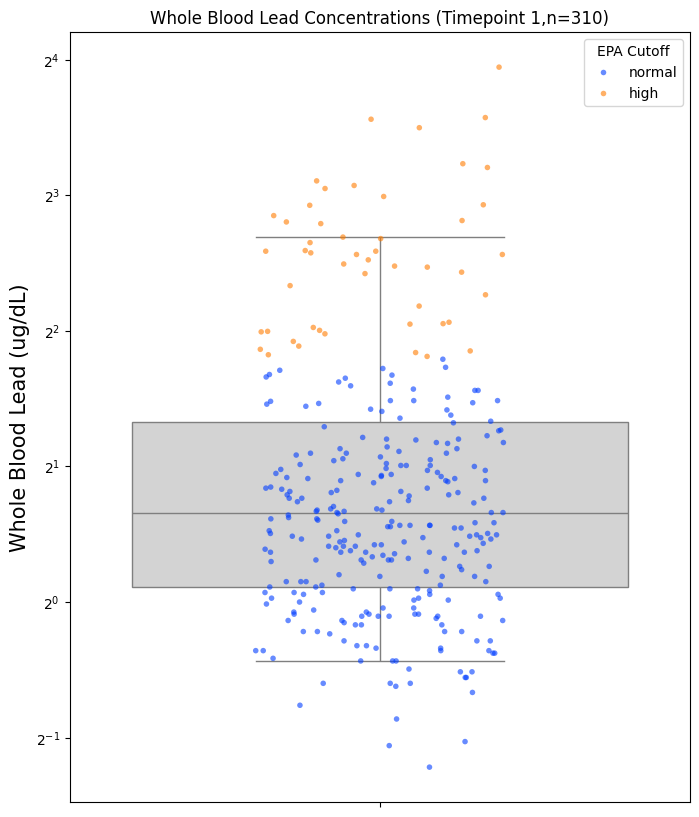

In [13]:
pb_t1 = Pb[Pb['Trimester_r'] == "1st/2nd"]
samples = pb_t1.shape[0]
print(pb_t1['EPA Cutoff'].value_counts())
fig, ax = plt.subplots(figsize=(8, 10))
sns.boxplot(
    data=pb_t1,
    y="Pb (ug/dL)",
    whis=[5, 95],
    fliersize=0,
    color="lightgray",
    ax=ax
)

sns.stripplot(
    data=pb_t1,
    y="Pb (ug/dL)",
    hue="EPA Cutoff",
    jitter=0.2,
    alpha=0.6,
    size=4,
    palette="bright",
    ax=ax
)

ax.set_yscale("log", base=2)
ax.set_ylabel("Whole Blood Lead (ug/dL)", fontsize=15)
ax.set_xlabel("")
ax.set_title(f"Whole Blood Lead Concentrations (Timepoint 1,n={samples})")

plt.show()

EPA Cutoff
normal    197
high       49
Name: count, dtype: int64


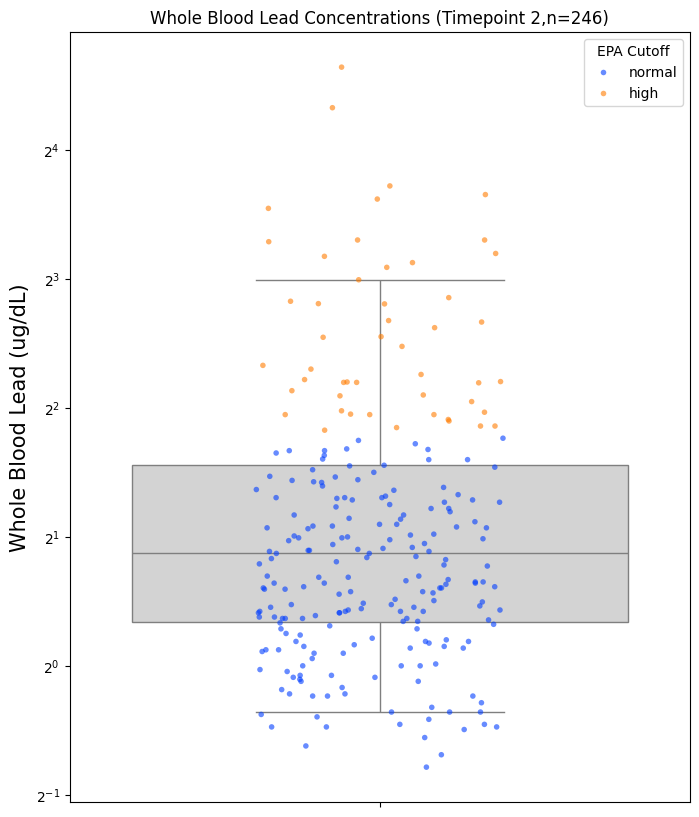

In [14]:
pb_t2 = Pb[Pb['Trimester_r'] == "3rd"]
samples = pb_t2.shape[0]
print(pb_t2['EPA Cutoff'].value_counts())
fig, ax = plt.subplots(figsize=(8, 10))
sns.boxplot(
    data=pb_t2,
    y="Pb (ug/dL)",
    whis=[5, 95],
    fliersize=0,
    color="lightgray",
    ax=ax
)

sns.stripplot(
    data=pb_t2,
    y="Pb (ug/dL)",
    hue="EPA Cutoff",
    jitter=0.2,
    alpha=0.6,
    size=4,
    palette="bright",
    ax=ax
)

ax.set_yscale("log", base=2)
ax.set_ylabel("Whole Blood Lead (ug/dL)", fontsize=15)
ax.set_xlabel("")
ax.set_title(f"Whole Blood Lead Concentrations (Timepoint 2,n={samples})")

plt.show()

In [20]:
obj = DifferentialAbundance(data=pb_untargeted_t1,metadata=pb_t1)
welch_Pb = obj.fit(contrast=("EPA Cutoff","high","normal"),applylog=True,equal_var=False)
welch_Pb = DifferentialAbundance.volcano_plot(welch_Pb,fc_thresh=0,use_adjusted=False,backend='plotly',title='Lead Exposure (EPA Cutoff)')
welch_Pb = welch_Pb[(welch_Pb['high_mean'] != 0) & (welch_Pb['normal_mean'] != 0)]
welch_Pb = pd.merge(welch_Pb,annotations,right_index=True,left_index=True,how='outer')

Contrast: EPA Cutoff[high vs normal]  (high: n=49, normal: n=261)  test=ttest  equal_var=False (Welch)  dof=per-feature


In [16]:
welch_Pb[welch_Pb['p_value'] < 0.05]['highest_OL'].value_counts()

highest_OL
PD_C     812
NM       467
OL_2a    174
OL_1      67
PD_D      66
PD_A      53
OL_2b     39
Name: count, dtype: int64

# Cadmium

In [21]:
Cd = targeted_data[['Cd (ng/mL)','Trimester_r']].copy()
Cd['Tertiles'] = pd.qcut(Cd['Cd (ng/mL)'],q=3,labels=['low','medium','high'])

cd_untargeted = untargeted_data.loc[untargeted_data.index.intersection(Cd.index),:]
cd_untargeted_t1 = cd_untargeted[cd_untargeted['Trimester'] == "1st/2nd"]
cd_untargeted_t1 = cd_untargeted_t1.drop(columns=['Trimester',"PID"])

Tertiles
low       121
high       98
medium     91
Name: count, dtype: int64


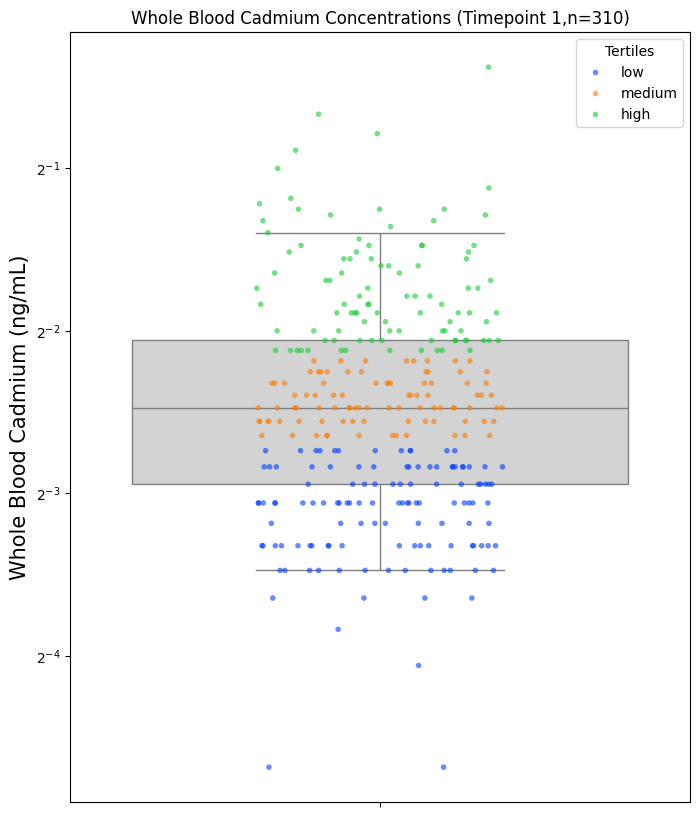

In [23]:
cd_t1 = Cd[Cd['Trimester_r'] == "1st/2nd"]
samples = cd_t1.shape[0]
print(cd_t1['Tertiles'].value_counts())
fig, ax = plt.subplots(figsize=(8, 10))
sns.boxplot(
    data=cd_t1,
    y="Cd (ng/mL)",
    whis=[5, 95],
    fliersize=0,
    color="lightgray",
    ax=ax
)

sns.stripplot(
    data=cd_t1,
    y="Cd (ng/mL)",
    hue="Tertiles",
    jitter=0.2,
    alpha=0.6,
    size=4,
    palette="bright",
    ax=ax
)

ax.set_yscale("log", base=2)
ax.set_ylabel("Whole Blood Cadmium (ng/mL)", fontsize=15)
ax.set_xlabel("")
ax.set_title(f"Whole Blood Cadmium Concentrations (Timepoint 1,n={samples})")

plt.show()

Tertiles
high      86
low       80
medium    80
Name: count, dtype: int64


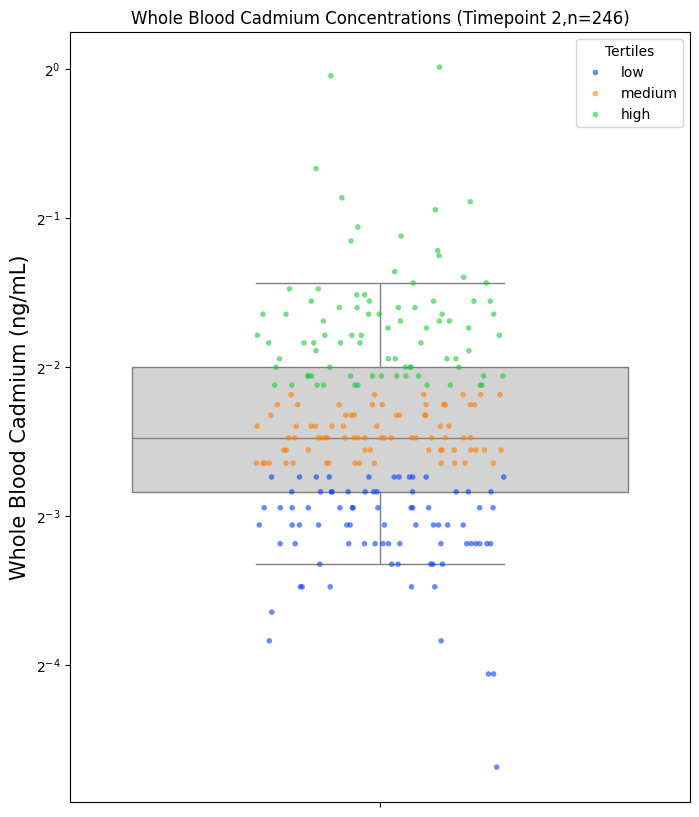

In [19]:
cd_t2 = Cd[Cd['Trimester_r'] == "3rd"]
samples = cd_t2.shape[0]
print(cd_t2['Tertiles'].value_counts())
fig, ax = plt.subplots(figsize=(8, 10))
sns.boxplot(
    data=cd_t2,
    y="Cd (ng/mL)",
    whis=[5, 95],
    fliersize=0,
    color="lightgray",
    ax=ax
)

sns.stripplot(
    data=cd_t2,
    y="Cd (ng/mL)",
    hue="Tertiles",
    jitter=0.2,
    alpha=0.6,
    size=4,
    palette="bright",
    ax=ax
)

ax.set_yscale("log", base=2)
ax.set_ylabel("Whole Blood Cadmium (ng/mL)", fontsize=15)
ax.set_xlabel("")
ax.set_title(f"Whole Blood Cadmium Concentrations (Timepoint 2,n={samples})")

plt.show()

In [24]:
obj = DifferentialAbundance(data=cd_untargeted_t1,metadata=cd_t1)
welch_Cd = obj.fit(contrast=("Tertiles","high","low"),applylog=True,equal_var=False)
welch_Cd = DifferentialAbundance.volcano_plot(welch_Cd,fc_thresh=0,use_adjusted=False,backend='plotly',title='Cadmium Exposure (Tertiles)')
welch_Cd = welch_Cd[(welch_Cd['high_mean'] != 0) & (welch_Cd['low_mean'] != 0)]
welch_Cd = pd.merge(welch_Cd,annotations,right_index=True,left_index=True,how='outer')

Dropping 91 sample(s) outside contrast levels {'medium'} for 'Tertiles'
Contrast: Tertiles[high vs low]  (high: n=98, low: n=121)  test=ttest  equal_var=False (Welch)  dof=per-feature


In [21]:
welch_Cd[welch_Cd['p_value'] < 0.05]['highest_OL'].value_counts()

highest_OL
PD_C     115
NM        79
OL_2a     29
PD_D      20
OL_2b      9
OL_1       8
PD_A       4
Name: count, dtype: int64

# Selenium

In [25]:
Se = targeted_data[['Se (ng/mL)','Trimester_r']].copy()
Se['Tertiles'] = pd.qcut(Se['Se (ng/mL)'],q=3,labels=['low','medium','high'])

se_untargeted = untargeted_data.loc[untargeted_data.index.intersection(Se.index),:]
se_untargeted_t1 = se_untargeted[se_untargeted['Trimester'] == "1st/2nd"]
se_untargeted_t1 = se_untargeted_t1.drop(columns=['Trimester',"PID"])

Tertiles
high      125
medium    107
low        78
Name: count, dtype: int64


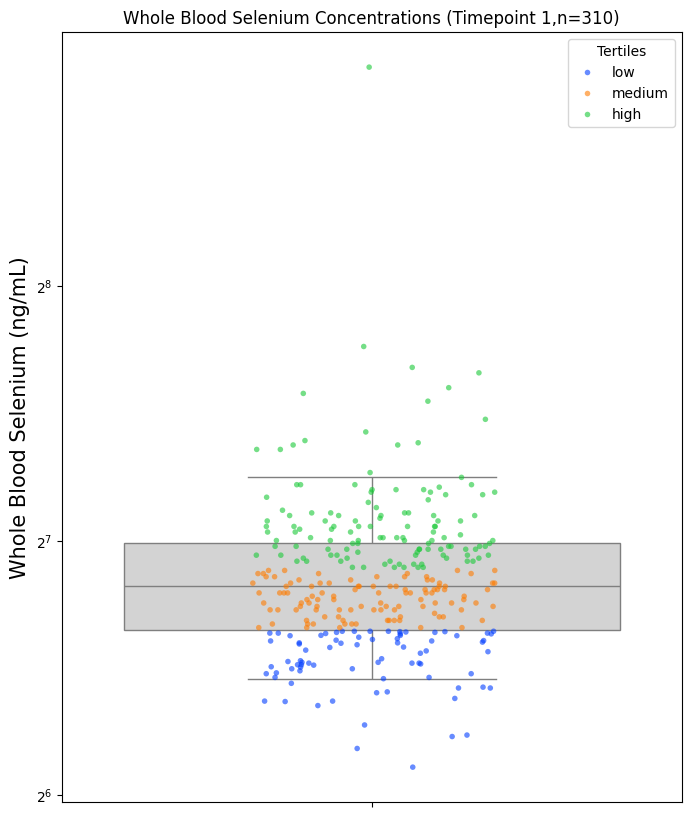

In [26]:
se_t1 = Se[Se['Trimester_r'] == "1st/2nd"]
samples = se_t1.shape[0]
print(se_t1['Tertiles'].value_counts())
fig, ax = plt.subplots(figsize=(8, 10))
sns.boxplot(
    data=se_t1,
    y="Se (ng/mL)",
    whis=[5, 95],
    fliersize=0,
    color="lightgray",
    ax=ax
)

sns.stripplot(
    data=se_t1,
    y="Se (ng/mL)",
    hue="Tertiles",
    jitter=0.2,
    alpha=0.6,
    size=4,
    palette="bright",
    ax=ax
)

ax.set_yscale("log", base=2)
ax.set_ylabel("Whole Blood Selenium (ng/mL)", fontsize=15)
ax.set_xlabel("")
ax.set_title(f"Whole Blood Selenium Concentrations (Timepoint 1,n={samples})")

plt.show()

Tertiles
low       110
medium     77
high       59
Name: count, dtype: int64


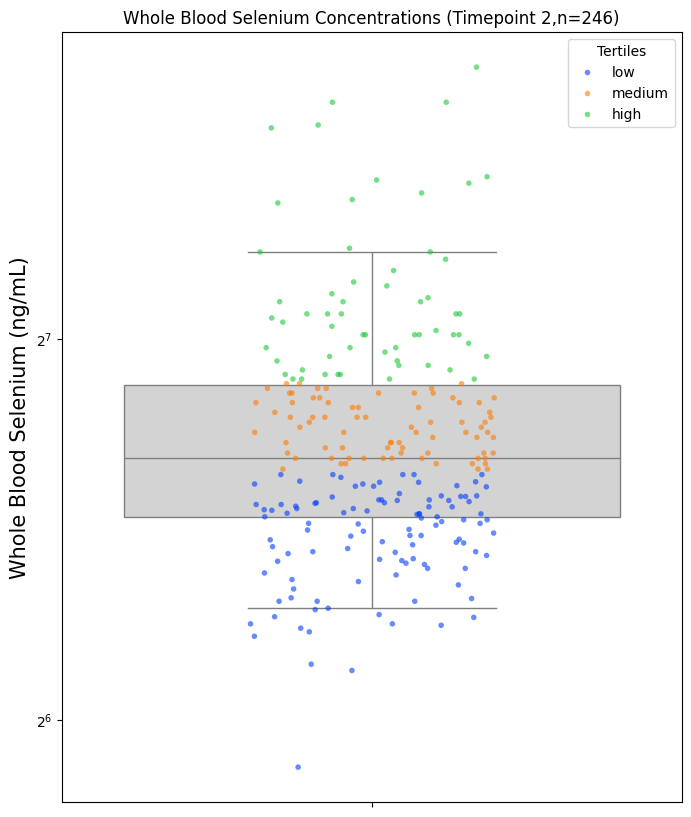

In [24]:
se_t2 = Se[Se['Trimester_r'] == "3rd"]
samples = se_t2.shape[0]
print(se_t2['Tertiles'].value_counts())
fig, ax = plt.subplots(figsize=(8, 10))
sns.boxplot(
    data=se_t2,
    y="Se (ng/mL)",
    whis=[5, 95],
    fliersize=0,
    color="lightgray",
    ax=ax
)

sns.stripplot(
    data=se_t2,
    y="Se (ng/mL)",
    hue="Tertiles",
    jitter=0.2,
    alpha=0.6,
    size=4,
    palette="bright",
    ax=ax
)

ax.set_yscale("log", base=2)
ax.set_ylabel("Whole Blood Selenium (ng/mL)", fontsize=15)
ax.set_xlabel("")
ax.set_title(f"Whole Blood Selenium Concentrations (Timepoint 2,n={samples})")

plt.show()

In [27]:
obj = DifferentialAbundance(data=se_untargeted_t1,metadata=se_t1)
welch_Se = obj.fit(contrast=("Tertiles","high","low"),applylog=True,equal_var=False)
welch_Se = DifferentialAbundance.volcano_plot(welch_Se,fc_thresh=0,use_adjusted=False,backend='plotly',title='Selenium Exposure (Tertiles)')
welch_Se = welch_Se[(welch_Se['high_mean'] != 0) & (welch_Se['low_mean'] != 0)]
welch_Se = pd.merge(welch_Se,annotations,right_index=True,left_index=True,how='outer')

Dropping 107 sample(s) outside contrast levels {'medium'} for 'Tertiles'
Contrast: Tertiles[high vs low]  (high: n=125, low: n=78)  test=ttest  equal_var=False (Welch)  dof=per-feature


In [26]:
welch_Se[welch_Se['p_value'] < 0.05]['highest_OL'].value_counts()

highest_OL
PD_C     370
NM       193
OL_2a     85
OL_1      40
PD_A      38
PD_D      29
OL_2b     14
Name: count, dtype: int64

# Manganese

In [14]:
Mn = targeted_data[['Mn (ng/mL)','Trimester_r']].copy()
Mn['Tertiles'] = pd.qcut(Mn['Mn (ng/mL)'],q=3,labels=['low','medium','high'])

mn_untargeted = untargeted_data.loc[untargeted_data.index.intersection(Mn.index),:]
mn_untargeted_t1 = mn_untargeted[mn_untargeted['Trimester'] == "1st/2nd"]
mn_untargeted_t1 = mn_untargeted_t1.drop(columns=['Trimester',"PID"])

Tertiles
low       142
medium    111
high       57
Name: count, dtype: int64


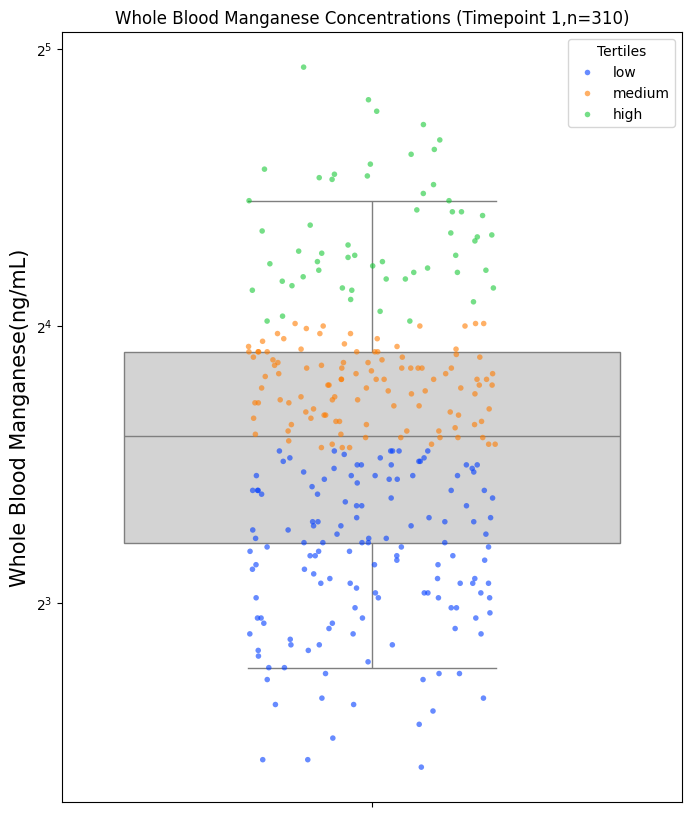

In [16]:
mn_t1 = Mn[Mn['Trimester_r'] == "1st/2nd"]
samples = mn_t1.shape[0]
print(mn_t1['Tertiles'].value_counts())
fig, ax = plt.subplots(figsize=(8, 10))
sns.boxplot(
    data=mn_t1,
    y="Mn (ng/mL)",
    whis=[5, 95],
    fliersize=0,
    color="lightgray",
    ax=ax
)

sns.stripplot(
    data=mn_t1,
    y="Mn (ng/mL)",
    hue="Tertiles",
    jitter=0.2,
    alpha=0.6,
    size=4,
    palette="bright",
    ax=ax
)

ax.set_yscale("log", base=2)
ax.set_ylabel("Whole Blood Manganese(ng/mL)", fontsize=15)
ax.set_xlabel("")
ax.set_title(f"Whole Blood Manganese Concentrations (Timepoint 1,n={samples})")

plt.show()

Tertiles
high      127
medium     74
low        45
Name: count, dtype: int64


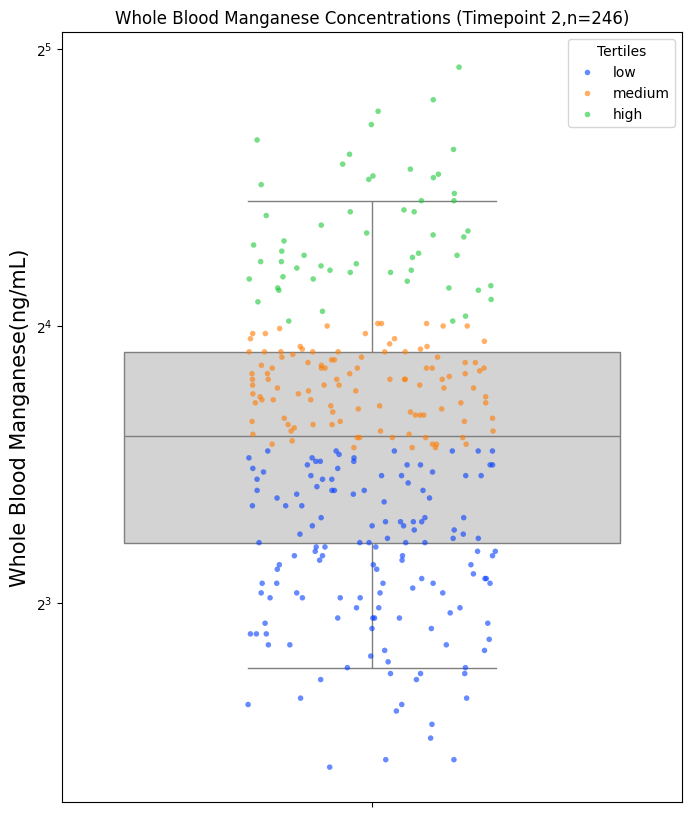

In [17]:
mn_t2 = Mn[Mn['Trimester_r'] == "3rd"]
samples = mn_t2.shape[0]
print(mn_t2['Tertiles'].value_counts())
fig, ax = plt.subplots(figsize=(8, 10))
sns.boxplot(
    data=mn_t1,
    y="Mn (ng/mL)",
    whis=[5, 95],
    fliersize=0,
    color="lightgray",
    ax=ax
)

sns.stripplot(
    data=mn_t1,
    y="Mn (ng/mL)",
    hue="Tertiles",
    jitter=0.2,
    alpha=0.6,
    size=4,
    palette="bright",
    ax=ax
)

ax.set_yscale("log", base=2)
ax.set_ylabel("Whole Blood Manganese(ng/mL)", fontsize=15)
ax.set_xlabel("")
ax.set_title(f"Whole Blood Manganese Concentrations (Timepoint 2,n={samples})")

plt.show()

In [18]:
obj = DifferentialAbundance(data=mn_untargeted_t1,metadata=mn_t1)
welch_Mn = obj.fit(contrast=("Tertiles","high","low"),applylog=True,equal_var=False)
welch_Mn = DifferentialAbundance.volcano_plot(welch_Mn,fc_thresh=0,use_adjusted=False,backend='plotly',title='Manganese Exposure (Tertiles)')
welch_Mn = welch_Mn[(welch_Mn['high_mean'] != 0) & (welch_Mn['low_mean'] != 0)]
welch_Mn = pd.merge(welch_Mn,annotations,right_index=True,left_index=True,how='outer')

Dropping 111 sample(s) outside contrast levels {'medium'} for 'Tertiles'
Contrast: Tertiles[high vs low]  (high: n=57, low: n=142)  test=ttest  equal_var=False (Welch)  dof=per-feature


In [22]:
welch_Mn[welch_Mn['highest_OL'] == "OL_1"].sort_values(by='p_value')

,log2FC,t_stat,p_value,p_adj,high_n,high_mean,high_median,high_std,low_n,low_mean,low_median,low_std,neg_log10_p,direction,feature,list_all_ids,list_all_library,highest_OL
11.40_346.2142n,0.663078,3.256229,0.001349,0.261042,57.0,12.583380,12.619708,0.999081,142.0,11.920302,12.119915,1.844348,2.869994,Up,11.40_346.2142n,5753 (Corticosterone) [OL_1] | 53477676 (CORTE...,Sumner in-house library_4_endogeous_positive_2...,OL_1
10.24_360.1935n,0.274177,3.209062,0.001740,0.293053,57.0,14.790345,14.748941,0.531898,142.0,14.516168,14.497149,0.575982,2.759463,Up,10.24_360.1935n,222786 (Cortisone) [OL_1] | Cortisone [PD_A] |...,Sumner in-house library_4_endogeous_positive_2...,OL_1
10.53_362.2090n,0.290221,2.804030,0.006066,0.480830,57.0,17.911136,17.946785,0.667482,142.0,17.620915,17.575945,0.641292,2.217071,Up,10.53_362.2090n,5754 (CORTISOL) [OL_1] | Hydrocortisone [PD_A]...,Sumner in-house library_4_endogeous_positive_2...,OL_1
5.23_182.0792m/z,0.292295,2.641725,0.009705,0.608740,57.0,9.609381,9.580033,0.732906,142.0,9.317086,9.285106,0.632661,2.013003,Up,5.23_182.0792m/z,227752 (N-Acetylvaline) [OL_1] | 4737557 (Vale...,Sumner in-house library_4_endogeous_positive_2...,OL_1
4.87_192.0655m/z,-0.345514,-2.436490,0.016545,0.706479,57.0,9.792377,9.928420,0.905151,142.0,10.137891,10.125052,0.902491,1.781345,Down,4.87_192.0655m/z,1826 (5-HYDROXYINDOLEACETATE) [OL_1] | 1826 (5...,Sumner in-house library_4_endogeous_positive_2...,OL_1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14.96_247.2421m/z,0.003524,0.028107,0.977637,0.996747,57.0,10.800720,11.039687,0.824588,142.0,10.797196,10.870993,0.733919,0.009822,Not significant,14.96_247.2421m/z,637517 (ELAIDATE) [OL_1] | 445639 (Oleic acid)...,Sumner in-house library_4_endogeous_positive_2...,OL_1
7.28_173.1052n,-0.008562,-0.026140,0.979199,0.997241,57.0,8.868825,9.146531,2.132887,142.0,8.877386,9.178158,1.974790,0.009129,Not significant,7.28_173.1052n,99463 (Hexanoyl Glycine) [OL_1] | 70912 (N-Ace...,Sumner in-house library_4_endogeous_positive_2...,OL_1
15.83_299.2821n,-0.002156,-0.022515,0.982086,0.998555,57.0,13.101744,13.148227,0.635046,142.0,13.103901,13.198406,0.545754,0.007850,Not significant,15.83_299.2821n,4671 (Palmitoylethanolamide) [OL_1] | Palmitoy...,Sumner in-house library_3_microbiome_positive_...,OL_1
0.96_156.0768m/z,0.005233,0.021383,0.982988,0.998912,57.0,14.720516,14.194152,1.635907,142.0,14.715283,14.280606,1.355482,0.007452,Not significant,0.96_156.0768m/z,6274 (HISTIDINE) [OL_1] | 6274 (L-Histidine) [...,Sumner in-house library_4_endogeous_positive_2...,OL_1


In [ ]:
# welch_Hg = welch_Hg.dropna(subset=['p_value'])
# welch_Pb = welch_Pb.dropna(subset=['p_value'])
# welch_Cd = welch_Cd.dropna(subset=['p_value'])
# welch_Se = welch_Se.dropna(subset=['p_value'])
# welch_Mn = welch_Mn.dropna(subset=['p_value'])

# welch_Hg.to_csv("Hg-DifferentialAbundance-T1-072026.csv",index=True)
# welch_Pb.to_csv("Pb-DifferentialAbundance-T1-072026.csv",index=True)
# welch_Cd.to_csv("Cd-DifferentialAbundance-T1-072026.csv",index=True)
# welch_Se.to_csv("Se-DifferentialAbundance-T1-072026.csv",index=True)
# welch_Mn.to_csv("Mn-DifferentialAbundance-T1-072026.csv",index=True)